# PCA and K-Means on MNIST
## Finding the structure of handwritten digits without using the labels

In the previous notebook we trained a network **with** the labels. Here we do the opposite: we forget the labels and ask what the data itself looks like. Everything is coded by hand with **NumPy**.

**Contents**
1. Data
2. PCA: principal components, explained variance and "eigen-digits"
3. Looking at the digits in 2D
4. Compressing and rebuilding the images
5. K-Means on the compressed data
6. Do the clusters match the real digits?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# Plot style used in the whole notebook
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'font.size': 10,
})
BLUE, ORANGE = '#2563eb', '#f97316'

## 1. Data

We load MNIST, normalize the pixels to $[0, 1]$ and keep a random sample of **10,000 images** so that everything runs quickly. The labels `y` are kept only at the end, to check the results. **PCA and K-Means never see them.**

In [2]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist['data'], mnist['target'].astype(np.int8)
X = X.astype('float64') / 255.0

# Random sample of 10,000 images
rng = np.random.default_rng(0)
idx = rng.choice(X.shape[0], 10000, replace=False)
X, y = X[idx], y[idx]

print(f"Sample: X = {X.shape}, y = {y.shape}")

Sample: X = (10000, 784), y = (10000,)


## 2. PCA from scratch

Each image is a point in a space of 784 dimensions. **PCA** finds the directions along which the images vary the most. The steps are:

1. **Center** the data: $X_c = X - \bar{X}$ (where $\bar{X}$ is the mean image).
2. Compute the **covariance matrix** $C = \dfrac{1}{N} X_c^T X_c$ (size $784 \times 784$).
3. Compute its **eigenvectors** $v_1, v_2, \dots$ (the principal components) and **eigenvalues** $\lambda_1 \geq \lambda_2 \geq \dots$.

The eigenvalue $\lambda_k$ is the variance of the data along $v_k$. The share of variance explained by a component is $\lambda_k / \sum_j \lambda_j$.

In [3]:
# 1. Center the data
mean = X.mean(axis=0)
Xc = X - mean

# 2. Covariance matrix
C = Xc.T @ Xc / Xc.shape[0]

# 3. Eigenvalues and eigenvectors (eigh is for symmetric matrices)
eigenvalues, eigenvectors = np.linalg.eigh(C)

# eigh sorts from the smallest to the largest, we want the opposite
eigenvalues = eigenvalues[::-1]
V = eigenvectors[:, ::-1]   # Column k of V is the k-th principal component

explained = eigenvalues / eigenvalues.sum()
cumulative = np.cumsum(explained)

for k in [2, 10, 50, 100, 200]:
    print(f"{k:>3} components -> {cumulative[k - 1]:.1%} of the variance")
print("Components needed for 90% of the variance:", np.argmax(cumulative >= 0.90) + 1)

  2 components -> 16.6% of the variance
 10 components -> 48.8% of the variance
 50 components -> 82.6% of the variance
100 components -> 91.6% of the variance
200 components -> 96.7% of the variance
Components needed for 90% of the variance: 86


### How many components do we need?
The curve below shows the variance kept when we only keep the first $k$ components. It rises very fast: a few dozen directions are enough to describe most of the 784 pixels.

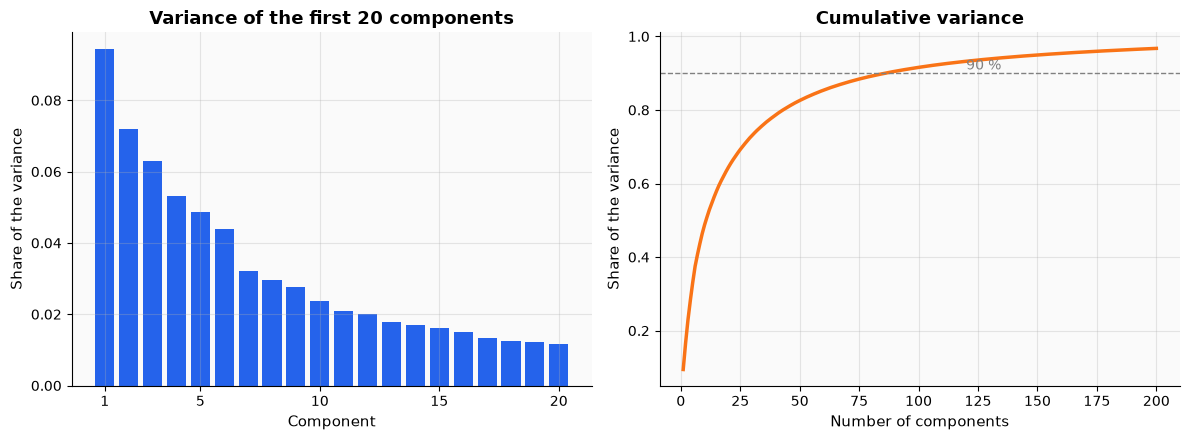

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(np.arange(1, 21), explained[:20], color=BLUE)
ax1.set_title('Variance of the first 20 components')
ax1.set_xlabel('Component')
ax1.set_ylabel('Share of the variance')
ax1.set_xticks([1, 5, 10, 15, 20])

ax2.plot(np.arange(1, 201), cumulative[:200], color=ORANGE, linewidth=2.5)
ax2.axhline(0.90, color='gray', linestyle='--', linewidth=1)
ax2.text(120, 0.91, '90 %', color='gray')
ax2.set_title('Cumulative variance')
ax2.set_xlabel('Number of components')
ax2.set_ylabel('Share of the variance')

plt.tight_layout()
plt.show()

### The "eigen-digits"
Each principal component has 784 values, so we can display it as an image. They are the basic patterns that PCA uses to describe any digit. Red pixels count positively, blue pixels negatively.

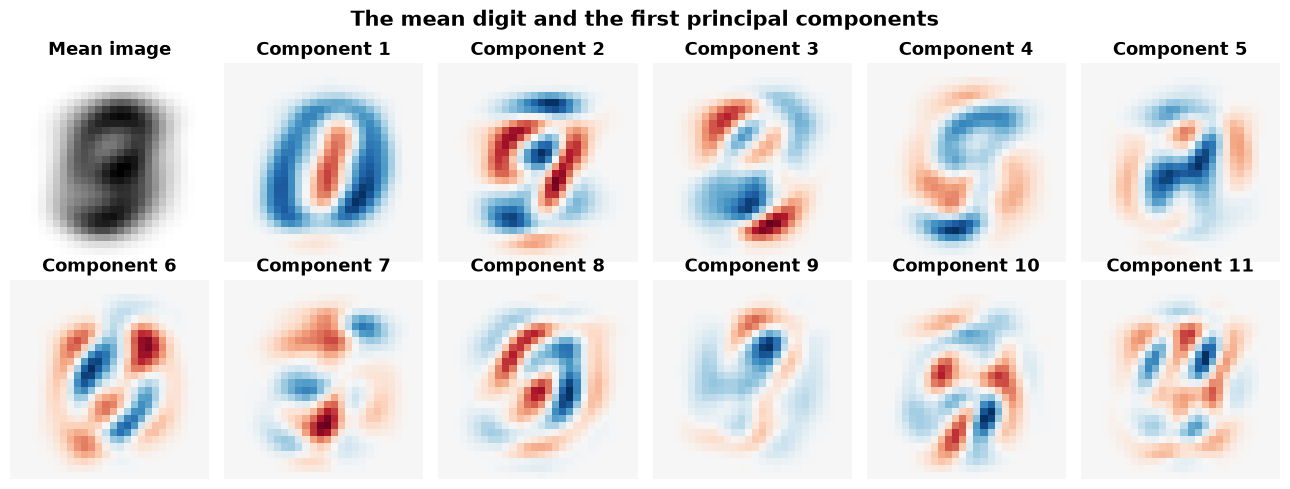

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))

# First image: the mean digit
axes[0, 0].imshow(mean.reshape(28, 28), cmap='gray_r')
axes[0, 0].set_title('Mean image')
axes[0, 0].axis('off')

# The next ones: the first 11 principal components
for k, ax in enumerate(axes.flatten()[1:]):
    v = np.abs(V[:, k]).max()
    ax.imshow(V[:, k].reshape(28, 28), cmap='RdBu_r', vmin=-v, vmax=v)
    ax.set_title(f"Component {k + 1}")
    ax.axis('off')

fig.suptitle("The mean digit and the first principal components", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Looking at the digits in 2D

We **project** each image on the first two components:

$$Z = X_c \, V_{[:, :2]}$$

Each image becomes a point $(z_1, z_2)$. We color the points with the real digit, only to see what PCA found without it.

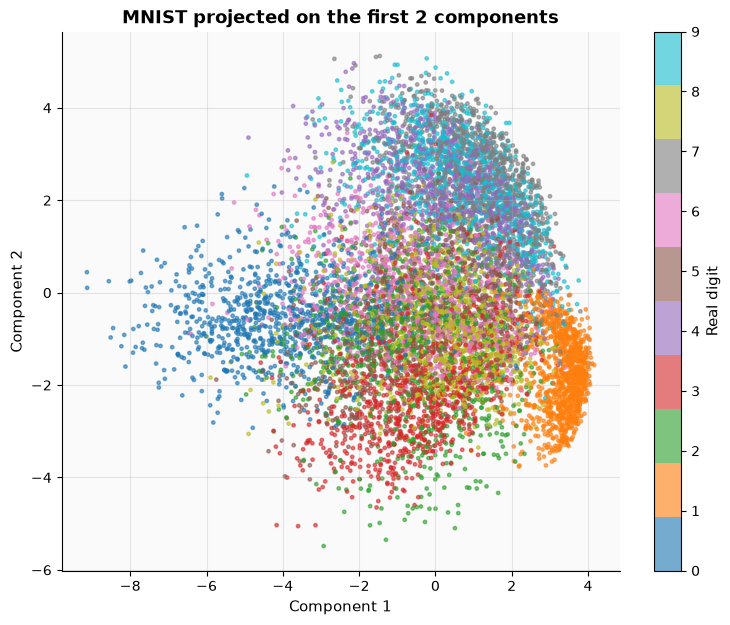

In [6]:
Z2 = Xc @ V[:, :2]

plt.figure(figsize=(9, 7))
scatter = plt.scatter(Z2[:, 0], Z2[:, 1], c=y, cmap='tab10', s=6, alpha=0.6)
plt.colorbar(scatter, ticks=range(10), label='Real digit')
plt.title('MNIST projected on the first 2 components')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.show()

Even with only 2 numbers per image (instead of 784), the digits already form groups: the **0s** and the **1s** are well separated, while digits like 4, 7 and 9 overlap. This is the part of the structure that two directions can capture.

## 4. Compressing and rebuilding the images

If we keep only the first $k$ components, each image is described by $k$ numbers instead of 784. We can **rebuild** an approximation of the image:

$$\hat{X} = X_c \, V_{[:, :k]} \, V_{[:, :k]}^T + \bar{X}$$

Let's see how the quality changes with $k$.

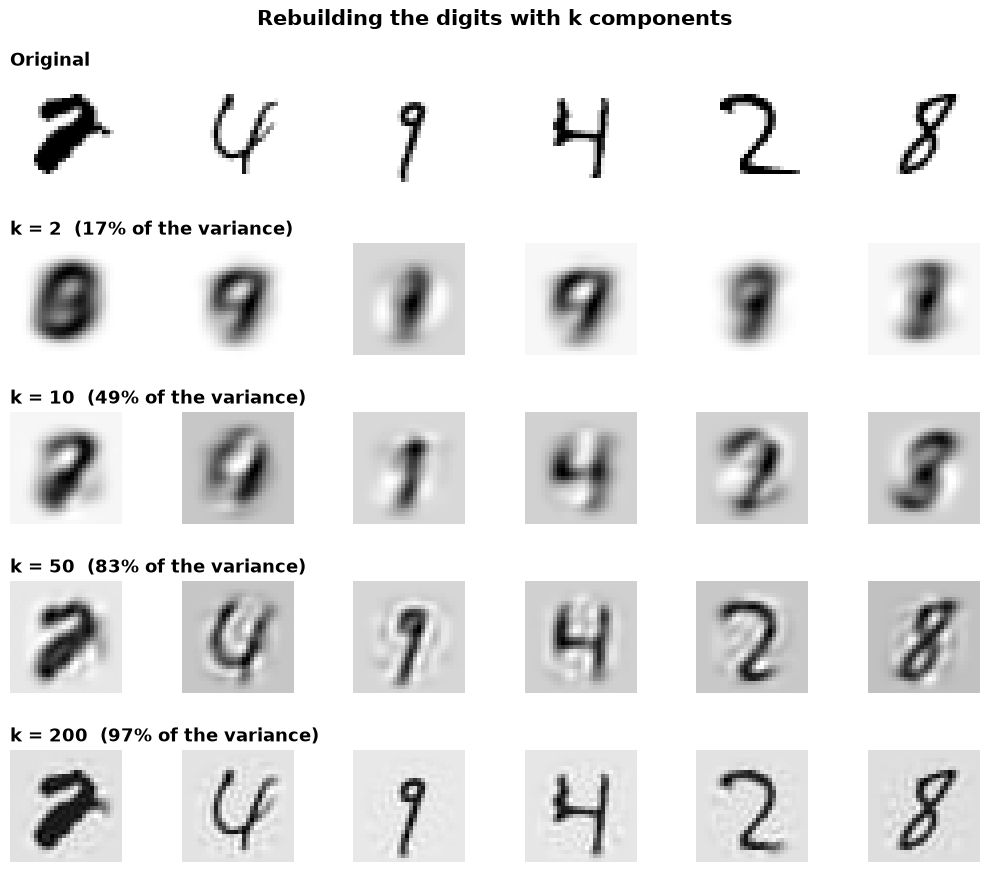

In [7]:
ks = [2, 10, 50, 200]
n_images = 6

fig, axes = plt.subplots(len(ks) + 1, n_images, figsize=(10, 9))

for j in range(n_images):
    axes[0, j].imshow(X[j].reshape(28, 28), cmap='gray_r')
    axes[0, j].axis('off')
axes[0, 0].set_title('Original', loc='left')

for i, k in enumerate(ks):
    Vk = V[:, :k]
    X_rebuilt = Xc[:n_images] @ Vk @ Vk.T + mean
    for j in range(n_images):
        axes[i + 1, j].imshow(X_rebuilt[j].reshape(28, 28), cmap='gray_r')
        axes[i + 1, j].axis('off')
    axes[i + 1, 0].set_title(f"k = {k}  ({cumulative[k - 1]:.0%} of the variance)", loc='left')

fig.suptitle("Rebuilding the digits with k components", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

With $k = 2$ we only see a blurry shape, with $k = 50$ every digit is clearly readable, and with $k = 200$ the image is almost identical to the original. So **50 numbers** are enough to keep the essential information of 784 pixels.

## 5. K-Means from scratch

K-Means groups the points in $K$ clusters. We choose $K = 10$ (one per digit, but the algorithm does not know the digits). The algorithm is:

1. Pick $K$ random points as the first **centroids**.
2. **Assign** each point to its nearest centroid.
3. **Move** each centroid to the mean of its points.
4. Repeat steps 2 and 3 until nothing changes.

At each step, the **inertia** (sum of the squared distances between each point and its centroid) decreases.

We run K-Means on the **first 50 components** (not on the 784 pixels): it is faster and the distances are less noisy.

In [8]:
Z = Xc @ V[:, :50]   # Each image is now described by 50 numbers

In [9]:
def kmeans(Z, K, max_iteration=100, seed=0):
    rng = np.random.default_rng(seed)
    centroids = Z[rng.choice(Z.shape[0], K, replace=False)]   # 1. Random start
    inertias = []

    for i in range(max_iteration):
        # 2. Squared distance between every point and every centroid
        dist = ((Z[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        labels = np.argmin(dist, axis=1)
        inertias.append(dist[np.arange(Z.shape[0]), labels].sum())

        # 3. Move each centroid to the mean of its points
        new_centroids = centroids.copy()
        for k in range(K):
            if np.any(labels == k):   # Keep the old centroid if the cluster is empty
                new_centroids[k] = Z[labels == k].mean(axis=0)

        # 4. Stop when nothing moves
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids

    return labels, centroids, inertias

The result depends on the random start, so we run K-Means with 5 different starts and keep the best one (the smallest final inertia).

In [10]:
best = None
for seed in range(5):
    labels, centroids, inertias = kmeans(Z, K=10, seed=seed)
    print(f"Start {seed}: {len(inertias)} iterations, final inertia = {inertias[-1]:.0f}")
    if best is None or inertias[-1] < best[2][-1]:
        best = (labels, centroids, inertias)

labels, centroids, inertias = best

Start 0: 100 iterations, final inertia = 299679


Start 1: 35 iterations, final inertia = 301097


Start 2: 77 iterations, final inertia = 299600


Start 3: 38 iterations, final inertia = 300102


Start 4: 63 iterations, final inertia = 299594


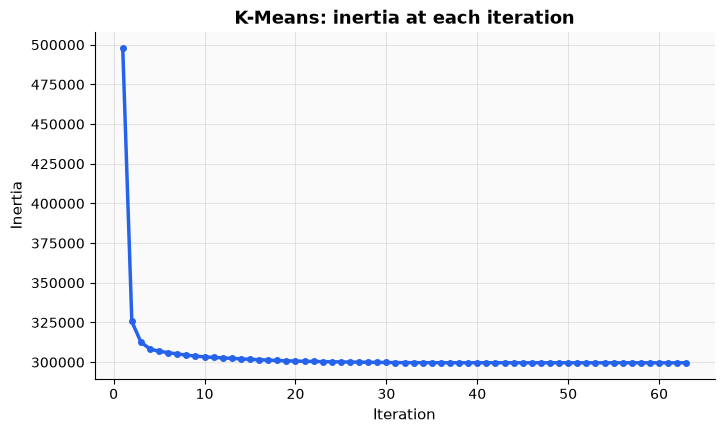

In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, len(inertias) + 1), inertias, color=BLUE, linewidth=2.5, marker='o', markersize=4)
plt.title('K-Means: inertia at each iteration')
plt.xlabel('Iteration')
plt.ylabel('Inertia')
plt.show()

### What does each cluster look like?
A centroid lives in the 50-dimensional space, but we can bring it back to the 784 pixels with the same formula as before. We get the **"average digit" of each cluster**.

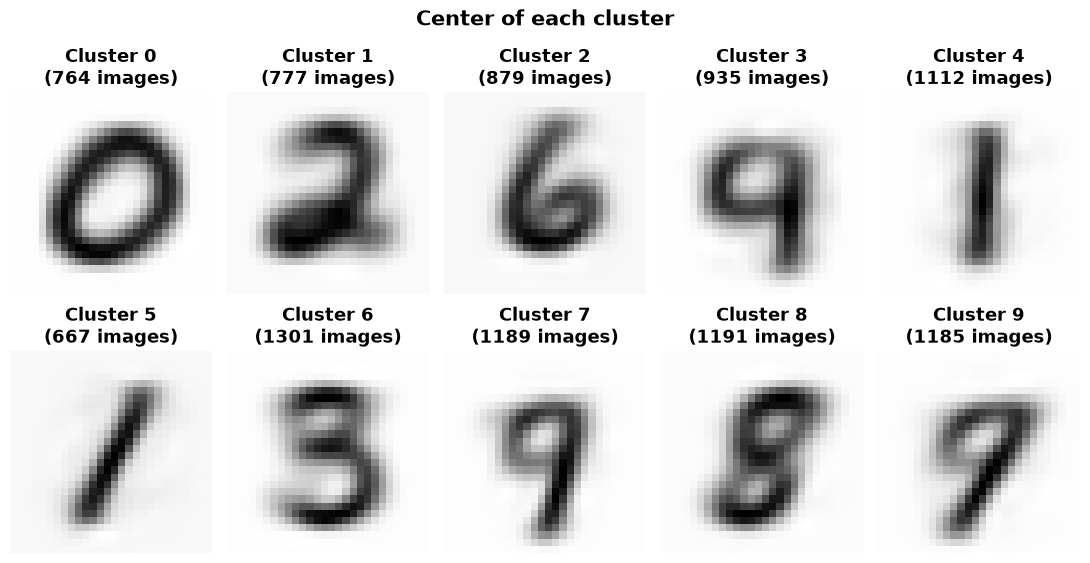

In [12]:
centroid_images = centroids @ V[:, :50].T + mean

fig, axes = plt.subplots(2, 5, figsize=(11, 6))
for k, ax in enumerate(axes.flatten()):
    ax.imshow(centroid_images[k].reshape(28, 28), cmap='gray_r')
    ax.set_title(f"Cluster {k}\n({np.sum(labels == k)} images)")
    ax.axis('off')
fig.suptitle("Center of each cluster", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Do the clusters match the real digits?

Now we use the labels, **only to check**. For each cluster we count how many images of each real digit it contains.

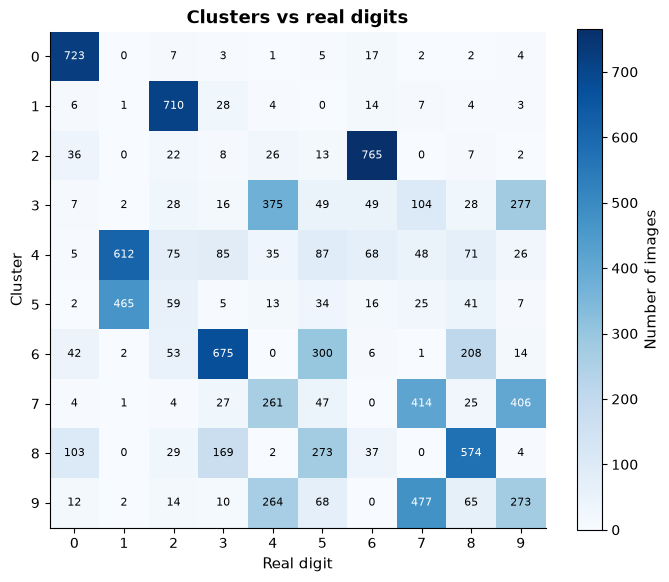

In [13]:
counts = np.zeros((10, 10), dtype=int)   # counts[cluster, digit]
for cluster, digit in zip(labels, y):
    counts[cluster, digit] += 1

plt.figure(figsize=(8, 6.5))
plt.imshow(counts, cmap='Blues')
plt.colorbar(label='Number of images')
for i in range(10):
    for j in range(10):
        color = 'white' if counts[i, j] > counts.max() / 2 else 'black'
        plt.text(j, i, counts[i, j], ha='center', va='center', color=color, fontsize=8)
plt.xticks(range(10))
plt.yticks(range(10))
plt.grid(False)
plt.title('Clusters vs real digits')
plt.xlabel('Real digit')
plt.ylabel('Cluster')
plt.show()

In [14]:
# Give to each cluster the most frequent digit inside it
cluster_digit = np.argmax(counts, axis=1)
predicted = cluster_digit[labels]

print("Digit given to each cluster:", cluster_digit)
print(f"Images in the right cluster: {np.mean(predicted == y):.2%}")

Digit given to each cluster: [0 2 6 4 1 1 3 7 8 7]
Images in the right cluster: 57.90%


Finally, the same 2D map as before, but colored with the clusters found by K-Means (without using the labels):

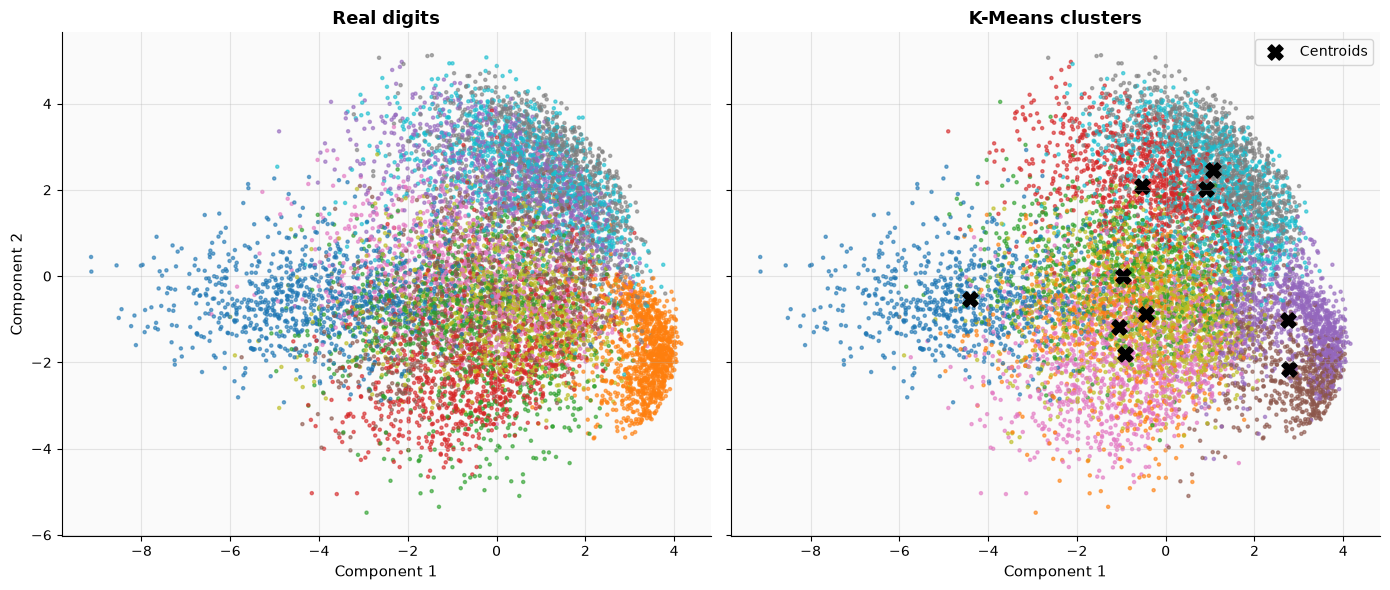

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

ax1.scatter(Z2[:, 0], Z2[:, 1], c=y, cmap='tab10', s=5, alpha=0.6)
ax1.set_title('Real digits')

ax2.scatter(Z2[:, 0], Z2[:, 1], c=labels, cmap='tab10', s=5, alpha=0.6)
ax2.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=120, label='Centroids')
ax2.set_title('K-Means clusters')
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel('Component 1')
ax1.set_ylabel('Component 2')

plt.tight_layout()
plt.show()

## Conclusion
- **PCA** shows that the 784 pixels are very redundant: 50 components keep 83 % of the variance (86 are enough for 90 %), and the digits are still clearly readable. The principal components are patterns we can look at.
- **K-Means**, without any label, finds clusters that look like digits. The 0s, 2s and 6s are found easily, and the 1s are even split into two clusters (upright and slanted).
- Digits that look alike are mixed: **4, 7 and 9** share the same clusters, and so do **3, 5 and 8**. K-Means never gives a cluster of its own to the 5s and the 9s, so only about 58 % of the images end in the "right" cluster.
- This is far from a network trained with labels (91 % in the previous notebook), but it needs no label at all.